Time Series on Economist data -> Bi-Yearly(6 months) data 
-- 
for y = 'local_price'

In [1]:
import pandas as pd
import numpy as np
from statsmodels.tsa.seasonal import seasonal_decompose # pip install statsmodels
import matplotlib.pyplot as plt
from sklearn.metrics import root_mean_squared_error
import os
os.chdir("C:/Users/dbda.STUDENTSDC/Desktop/Practical Machine Learning/Datasets")

In [2]:
df = pd.read_csv("BUNDESBANK-BBK01_WT5511.csv")
df

,Date,Value
0,30-04-1968,39.10
1,31-05-1968,42.00
2,30-06-1968,40.95
3,31-07-1968,38.90
4,31-08-1968,39.85
...,...,...
572,31-12-2015,1062.25
573,31-01-2016,1112.90
574,29-02-2016,1234.15
575,31-03-2016,1233.60


Train Test split
-

In [4]:
y_train = df['Value'].iloc[:-12]   # except last 12
y_test = df['Value'].iloc[-12:]    # Gets the last 12 observations
y_test

565    1190.40
566    1175.00
567    1080.05
568    1125.50
569    1122.50
570    1147.75
571    1055.65
572    1062.25
573    1112.90
574    1234.15
575    1233.60
576    1237.70
Name: Value, dtype: float64

## Simple Exponential Method

In [5]:
from statsmodels.tsa.api import SimpleExpSmoothing

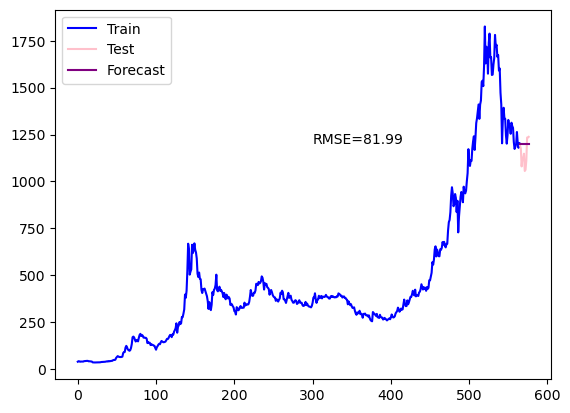

In [10]:
alpha = 0.7
ses_model = SimpleExpSmoothing(y_train).fit(smoothing_level=alpha,optimized=False)
fcast1 = ses_model.forecast(len(y_test))
y_train.plot(color="blue", label='Train')
y_test.plot(color="pink",label='Test')
fcast1.plot(color="purple",label='Forecast')
rms = np.round(root_mean_squared_error(y_test, fcast1),2)
plt.text(300,1200, f"RMSE={rms}")
plt.legend(loc='best')
plt.show()

Auto tune parameters & optimized =True

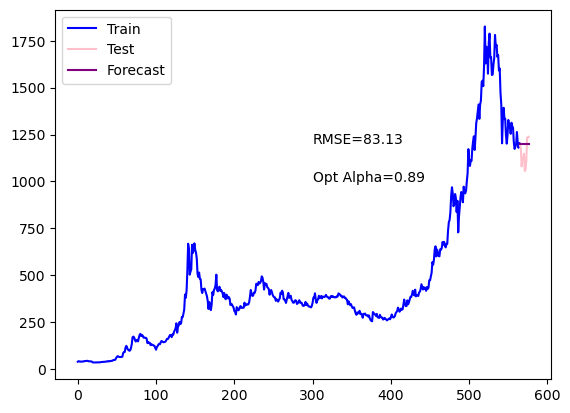

In [11]:
ses_model = SimpleExpSmoothing(y_train).fit(optimized=True)
fcast1 = ses_model.forecast(len(y_test))
y_train.plot(color="blue", label='Train')
y_test.plot(color="pink",label='Test')
fcast1.plot(color="purple",label='Forecast')
rms = np.round(root_mean_squared_error(y_test, fcast1),2)
opt_alpha = np.round(ses_model.model.params['smoothing_level'],2)
plt.text(300,1000,f"Opt Alpha={opt_alpha}")
plt.text(300,1200, f"RMSE={rms}")
plt.legend(loc='best')
plt.show()

Holt's Linear Trend
-

In [9]:
from statsmodels.tsa.api import Holt

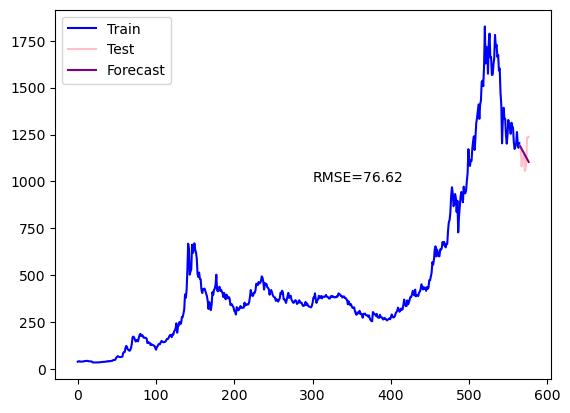

In [29]:
alpha, beta = 0.7,0.1
holt = Holt(y_train)
fit1 = holt.fit(smoothing_level=alpha,smoothing_trend=beta,optimized=False)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color="blue", label='Train')
y_test.plot(color="pink",label='Test')
fcast1.plot(color="purple",label='Forecast')
rms = np.round(root_mean_squared_error(y_test, fcast1),2)
plt.text(300,1000, f"RMSE={rms}")
plt.legend(loc='best')
plt.show()

Auto tune parameters

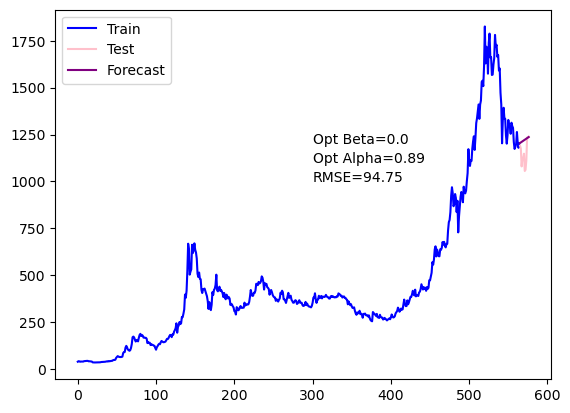

In [13]:
holt = Holt(y_train)
fit1 = holt.fit(optimized=True)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color="blue", label='Train')
y_test.plot(color="pink",label='Test')
fcast1.plot(color="purple",label='Forecast')
rms = np.round(root_mean_squared_error(y_test, fcast1),2)
plt.text(300,1000, f"RMSE={rms}")
plt.text(300,1100,f"Opt Alpha={np.round(fit1.params['smoothing_level'], 2)}")
plt.text(300,1200,f"Opt Beta={np.round(fit1.params['smoothing_trend'], 2)}")
plt.legend(loc='best')
plt.show()

Holt's Exponential Trend
--

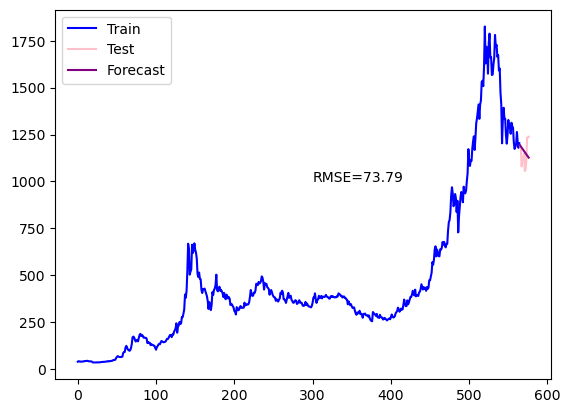

In [28]:
alpha, beta = 0.8,0.1
holt = Holt(y_train,exponential=True)
fit1 = holt.fit(smoothing_level=alpha,smoothing_trend=beta,optimized=False)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color="blue", label='Train')
y_test.plot(color="pink",label='Test')
fcast1.plot(color="purple",label='Forecast')
rms = np.round(root_mean_squared_error(y_test, fcast1),2)
plt.text(300,1000, f"RMSE={rms}")
plt.legend(loc='best')
plt.show()

Auto tune parameters

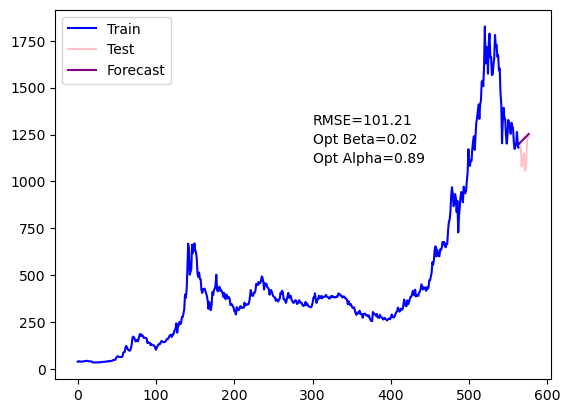

In [19]:
holt = Holt(y_train,exponential=True)
fit1 = holt.fit(optimized=True)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color="blue", label='Train')
y_test.plot(color="pink",label='Test')
fcast1.plot(color="purple",label='Forecast')
rms = np.round(root_mean_squared_error(y_test, fcast1),2)
plt.text(300,1100,f"Opt Alpha={np.round(fit1.params['smoothing_level'], 2)}")
plt.text(300,1200,f"Opt Beta={np.round(fit1.params['smoothing_trend'], 2)}")
plt.text(300,1300, f"RMSE={rms}")
plt.legend(loc='best')
plt.show()

Additive Damp Trend
-

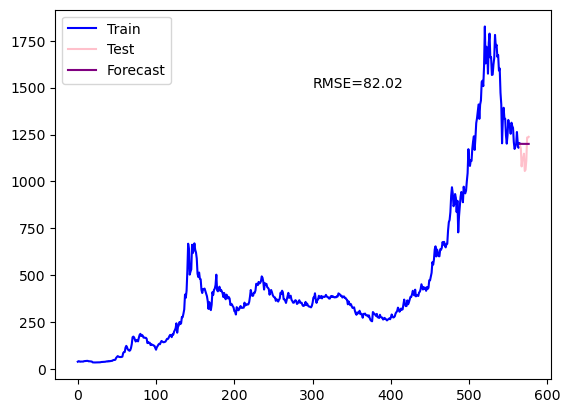

In [25]:
alpha, beta,phi = 0.8,0.02,0.7
holt = Holt(y_train,damped_trend=True)
fit1 = holt.fit(smoothing_level=alpha,smoothing_trend=beta,damping_trend=phi,optimized=False)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color="blue", label='Train')
y_test.plot(color="pink",label='Test')
fcast1.plot(color="purple",label='Forecast')
rms = np.round(root_mean_squared_error(y_test, fcast1),2)
plt.text(300,1500, f"RMSE={rms}")
plt.legend(loc='best')
plt.show()

Auto tune parameters

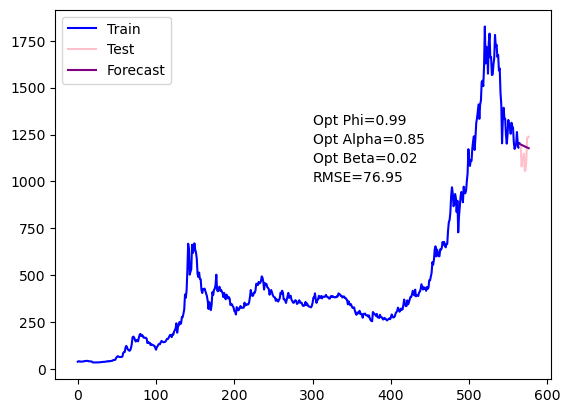

In [26]:
holt = Holt(y_train,damped_trend=True)
fit1 = holt.fit(optimized=True)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color="blue", label='Train')
y_test.plot(color="pink",label='Test')
fcast1.plot(color="purple",label='Forecast')
rms = np.round(root_mean_squared_error(y_test, fcast1),2)
plt.text(300,1000, f"RMSE={rms}")
plt.text(300,1200,f"Opt Alpha={np.round(fit1.params['smoothing_level'], 2)}")
plt.text(300,1100,f"Opt Beta={np.round(fit1.params['smoothing_trend'], 2)}")
plt.text(300,1300,f"Opt Phi={np.round(fit1.params['damping_trend'], 2)}")
plt.legend(loc='best')
plt.show()